## Descrição das colunas — Dados eleitorais do TSE

O DataFrame `df_candidatos` contém informações dos candidatos à Presidência da República, obtidas por meio da API do Tribunal Superior Eleitoral (TSE).

| Coluna | Descrição |
|---|---|
| `numero` | Número eleitoral do candidato. |
| `nome` | Nome completo do candidato. |
| `nome_urna` | Nome apresentado na urna eletrônica. |
| `partido` | Sigla do partido político. |
| `votos` | Quantidade de votos recebidos pelo candidato. |
| `percentual` | Percentual de votos válidos obtidos pelo candidato. |
| `situacao` | Situação eleitoral: eleito, não eleito ou classificado para o segundo turno. |
| `eleito` | Indicador retornado pelo TSE (`s` ou `n`), associado à situação de eleição ou classificação. |

**Fonte:** [Tribunal Superior Eleitoral (TSE)](https://resultados.tse.jus.br/)

In [1]:
import requests
import pandas as pd

# ============================================================
# CONFIGURAÇÕES
# ============================================================

url = "https://resultados.tse.jus.br"

ambiente = "oficial"

ciclo = "ele2026" # para 2022 "ele2022" (1º turno em 2022 codigo_eleicao = 544 | 2º turno em 2022 codigo_eleicao = 545)

codigo_eleicao = 6257 # para segundo turno (1º turno: 6257)

codigo_eleicao_formatado = f"{codigo_eleicao:06d}"

codigo_cargo = "0001"  # Presidente

url = f"{url}/{ambiente}/{ciclo}/{codigo_eleicao}/dados/br/br-c{codigo_cargo}-e{codigo_eleicao_formatado}-u.json"

resposta = requests.get(url)

dados = resposta.json()

# ============================================================
# LISTA COM TODOS OS VOTOS
# ============================================================

lista_candidatos = []

for cargo in dados["carg"]:

    for agrupamento in cargo["agr"]:

        for partido in agrupamento["par"]:

            for candidato in partido["cand"]:

                lista_candidatos.append({

                    "numero": candidato["n"],

                    "nome": candidato["nm"],

                    "nome_urna": candidato["nmu"],

                    "partido": partido["sg"],

                    "votos": candidato["vap"],

                    "percentual": candidato["pvap"],

                    "situacao": candidato["st"],

                    "eleito": candidato["e"]

                })

df_candidatos = pd.DataFrame(lista_candidatos)

df_candidatos

,numero,nome,nome_urna,partido,votos,percentual,situacao,eleito
0,22,FLAVIO NANTES BOLSONARO,FLAVIO BOLSONARO,PL,56104503,"47,03",2º turno,s
1,55,RONALDO RAMOS CAIADO,RONALDO CAIADO,PSD,2605148,"2,18",Não eleito,n
2,13,LUIZ INÁCIO LULA DA SILVA,LULA,PT,53879538,"45,16",2º turno,s
3,27,CLARIANA ZACARKIM BARAO,CLARIANA BARAO,DC,40043,"0,03",Não eleito,n
4,21,EDMILSON SILVA COSTA,EDMILSON COSTA,PCB,22693,"0,02",Não eleito,n
5,16,HERTZ DA CONCEICAO DIAS,HERTZ DIAS,PSTU,43103,"0,04",Não eleito,n
6,70,AUGUSTO JORGE CURY,ESCRITOR AUGUSTO CURY,AVANTE,3448569,"2,89",Não eleito,n
7,30,ROMEU ZEMA NETO,ZEMA,NOVO,326488,"0,27",Não eleito,n
8,80,SAMARA MARTINS DA SILVA FEITOSA,SAMARA,UP,122911,"0,10",Não eleito,n
9,35,WILSON GRASSI JUNIOR,VETERINÁRIO WILSON GRASSI,DEMOCRATA,16881,"0,01",Não eleito,n


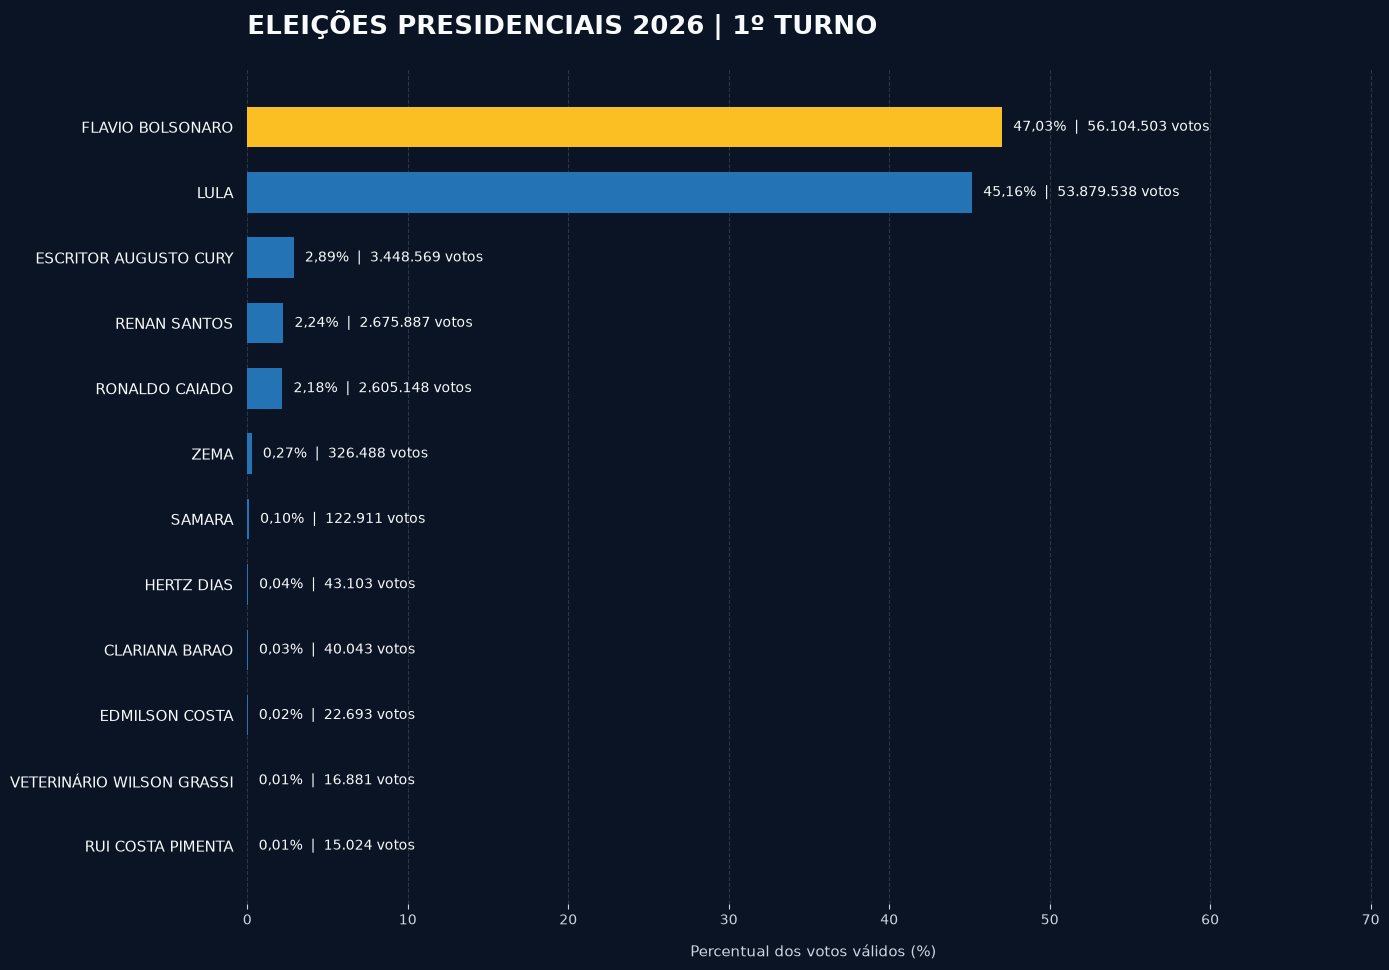

In [2]:
# ANÁLISE GRÁFICA

import matplotlib.pyplot as plt
import pandas as pd

# Cria uma cópia do DataFrame original
df_grafico = df_candidatos.copy()

# Converte os votos para números inteiros
df_grafico["votos"] = pd.to_numeric(
    df_grafico["votos"], errors="coerce"
).fillna(0).astype(int)

# Converte os percentuais para números decimais
df_grafico["percentual"] = pd.to_numeric(
    df_grafico["percentual"].astype(str).str.replace(",", "."),
    errors="coerce"
).fillna(0)

# Ordena os candidatos pela quantidade de votos
df_grafico = df_grafico.sort_values("votos")

# Identifica a maior votação
maior_votacao = df_grafico["votos"].max()

# Só destaca um líder quando há votos e não existe empate
tem_lider = (
    maior_votacao > 0
    and (df_grafico["votos"] == maior_votacao).sum() == 1
)

# Define uma paleta de cores
cor_destaque = "#FBBF24"  # Dourado
cor_padrao = "#2474B5"    # Azul
cor_fundo = "#0B1424"     # Azul-escuro
cor_texto = "#F8FAFC"     # Branco

# Aplica dourado ao candidato com maior votação
cores = [
    cor_destaque if tem_lider and votos == maior_votacao
    else cor_padrao
    for votos in df_grafico["votos"]
]

# Ajusta a altura da figura conforme o número de candidatos
altura = max(4.5, len(df_grafico) * 0.65 + 2)

# Cria a figura
fig, ax = plt.subplots(figsize=(14, altura))

# Define as cores de fundo
fig.patch.set_facecolor(cor_fundo)
ax.set_facecolor(cor_fundo)

# Cria o gráfico de barras horizontais
barras = ax.barh(
    df_grafico["nome_urna"],
    df_grafico["percentual"],
    color=cores,
    height=0.62
)

# Adiciona o percentual e o número de votos em cada barra
for barra, percentual, votos in zip(
    barras,
    df_grafico["percentual"],
    df_grafico["votos"]
):
    # Formata os números para o padrão brasileiro
    percentual_texto = f"{percentual:.2f}".replace(".", ",")
    votos_texto = f"{votos:,}".replace(",", ".")

    # Posiciona os rótulos à direita de cada barra
    ax.text(
        barra.get_width() + 0.7,
        barra.get_y() + barra.get_height() / 2,
        f"{percentual_texto}%  |  {votos_texto} votos",
        va="center",
        fontsize=10,
        color=cor_texto
    )

# Identifica o turno pelo código da eleição
turno = "2º TURNO" if codigo_eleicao == 6258 else "1º TURNO"

# Define o título
ax.set_title(
    f"ELEIÇÕES PRESIDENCIAIS 2026 | {turno}",
    fontsize=19,
    fontweight="bold",
    color=cor_texto,
    loc="left",
    pad=25
)

# Configura o eixo horizontal
ax.set_xlabel(
    "Percentual dos votos válidos (%)",
    fontsize=11,
    color="#CBD5E1",
    labelpad=12
)

# Ajusta o limite para acomodar os rótulos
ax.set_xlim(
    0,
    max(65, df_grafico["percentual"].max() * 1.5)
)

# Personaliza os eixos
ax.tick_params(axis="x", colors="#CBD5E1", labelsize=10)
ax.tick_params(axis="y", colors=cor_texto, labelsize=11, length=0, pad=10)

# Adiciona linhas de grade discretas
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", alpha=0.15, color="white")

# Remove as bordas do gráfico
for borda in ax.spines.values():
    borda.set_visible(False)

# Exibe uma mensagem caso ainda não existam votos apurados
if df_grafico["votos"].sum() == 0:
    ax.text(
        0.5, 0.5,
        "Aguardando votos apurados",
        transform=ax.transAxes,
        ha="center",
        color=cor_texto,
        fontsize=15
    )

# Ajusta automaticamente o espaçamento
plt.tight_layout()

# Exibe o gráfico
plt.show()

| Coluna | Descrição / cálculo |
|---|---|
| `estado` | Nome do estado onde está localizado o município. |
| `uf` | Sigla da Unidade Federativa, como `PB`, `SC`, `SP`. |
| `municipio` | Nome do município onde os votos foram contabilizados. |
| `codigo_tse` | Código utilizado pelo TSE para identificar o município. Também é utilizado para montar a URL de consulta dos resultados. |
| `codigo_ibge` | Código do município segundo o IBGE. Pode ser utilizado para cruzar os dados eleitorais com mapas e indicadores socioeconômicos. |
| `numero_candidato` | Número eleitoral do candidato à Presidência. |
| `nome_candidato` | Nome completo do candidato registrado no TSE. |
| `nome_urna` | Nome do candidato apresentado ao eleitor na urna eletrônica. |
| `partido` | Sigla do partido político do candidato. |
| `destinacao_voto` | Indica como os votos recebidos pelo candidato serão considerados na totalização. |
| `situacao` | Situação do candidato no processo eleitoral, conforme informação do TSE. |
| `eleito` | Indicador fornecido pelo TSE sobre a situação eleitoral do candidato. |
| `votos_candidato` | Quantidade de votos recebidos pelo candidato naquele município. |
| `percentual_candidato` | Percentual de votos obtidos pelo candidato no município. |
| `percentual_candidato_preciso` | Versão mais precisa do percentual de votos do candidato, quando disponível no JSON. |
| `total_votos` | Total de votos contabilizados no município para o cargo de Presidente. |
| `votos_validos` | Total de votos considerados válidos para os candidatos. |
| `votos_brancos` | Quantidade de votos em branco registrados no município. |
| `total_votos_nulos` | Total de votos nulos. Corresponde aos votos nulos comuns somados aos nulos técnicos. |
| `votos_nulos` | Quantidade de votos nulos comuns. |
| `votos_nulos_tecnicos` | Quantidade de votos classificados tecnicamente como nulos pelo sistema de totalização. |
| `votos_anulados` | Quantidade de votos anulados conforme as regras da Justiça Eleitoral. |
| `votos_anulados_sub_judice` | Quantidade de votos anulados relacionados a situações que ainda dependem de decisão judicial. |
| `votos_invalidos` | Coluna criada no código. Cálculo: `total_votos_nulos + votos_anulados + votos_anulados_sub_judice`. |
| `votos_nao_validos` | Coluna criada no código. Cálculo: `votos_brancos + votos_invalidos`. |
| `votos_sem_candidato` | Quantidade de votos registrados sem candidato correspondente, quando essa situação existir. |
| `votos_secoes_anuladas` | Quantidade de votos relacionados a seções eleitorais anuladas, quando aplicável. |
| `eleitorado` | Quantidade total de eleitores aptos a votar naquela abrangência. |
| `comparecimento` | Quantidade de eleitores que compareceram para votar. |
| `abstencoes` | Quantidade de eleitores que não compareceram. Conceitualmente: `eleitorado - comparecimento`. |
| `total_secoes` | Quantidade total de seções eleitorais existentes no município. |
| `secoes_totalizadas` | Quantidade de seções que já tiveram seus resultados incorporados à totalização. |
| `secoes_nao_totalizadas` | Quantidade de seções que ainda não foram incorporadas à totalização. |
| `percentual_secoes_totalizadas` | Percentual das seções eleitorais que já foram totalizadas. |
| `andamento` | Indica o estágio atual da totalização dos votos. |
| `totalizacao_final` | Indica se a totalização daquele resultado já foi finalizada. |
| `data_totalizacao` | Data relacionada à totalização dos resultados. |
| `hora_totalizacao` | Horário relacionado à totalização dos resultados. |
| `data_geracao` | Data em que o arquivo JSON foi gerado pelo sistema do TSE. |
| `hora_geracao` | Horário em que o arquivo JSON foi gerado pelo sistema do TSE. |

In [ ]:
import requests
import pandas as pd
import time

# ============================================================
# CONFIGURAÇÕES
# ============================================================

url_base = "https://resultados.tse.jus.br"

ambiente = "oficial"

ciclo = "ele2026" # para 2022 "ele2022" (1º turno em 2022 codigo_eleicao = 544 | 2º turno em 2022 codigo_eleicao = 545)

codigo_eleicao = 6258 # para segundo turno, ver o código que será disponibilizado pelo o TSE (1º turno: 6257)

codigo_eleicao_formatado = f"{codigo_eleicao:06d}"

codigo_cargo = "0001"  # Presidente



"""
| Cargo              | Código |

| Presidente         | `0001` |
| Governador         | `0003` |
| Senador            | `0005` |
| Deputado Federal   | `0006` |
| Deputado Estadual  | `0007` |
| Deputado Distrital | `0008` |
| Prefeito           | `0011` |
| Vereador           | `0013` |
"""

# ============================================================
# 1. BUSCAR LISTA OFICIAL DE MUNICÍPIOS
# ============================================================

url_municipios = (
    f"{url_base}/"
    f"{ambiente}/"
    f"{ciclo}/"
    f"{codigo_eleicao}/"
    f"config/"
    f"mun-e{codigo_eleicao_formatado}-cm.json"
)


resposta = requests.get(
    url_municipios,
    timeout=30
)

resposta.raise_for_status()

dados_municipios = resposta.json()


# ============================================================
# 2. CRIAR LISTA COM TODOS OS MUNICÍPIOS
# ============================================================

municipios = []

for estado in dados_municipios["abr"]:

    uf = estado["cd"].lower()

    nome_estado = estado["ds"]

    # Ignora localidades do exterior
    if uf == "zz":
        continue

    for municipio in estado["mu"]:

        codigo_tse = str(
            municipio["cd"]
        ).zfill(5)

        codigo_ibge = str(
            municipio.get("cdi", "")
        ).zfill(5)

        nome_municipio = municipio["nm"]

        municipios.append({

            "uf": uf,

            "estado": nome_estado,

            "codigo_tse": codigo_tse,

            "codigo_ibge": codigo_ibge,

            "municipio": nome_municipio

        })


print(
    "Quantidade de municípios encontrados:",
    len(municipios)
)


# ============================================================
# 3. LISTA QUE RECEBERÁ TODOS OS RESULTADOS
# ============================================================

resultados = []


# ============================================================
# 4. PERCORRER TODOS OS MUNICÍPIOS DO BRASIL
# ============================================================

for indice, municipio in enumerate(municipios, start=1):

    uf = municipio["uf"]

    estado = municipio["estado"]

    codigo_tse = municipio["codigo_tse"]

    codigo_ibge = municipio["codigo_ibge"]

    nome_municipio = municipio["municipio"]


    # --------------------------------------------------------
    # URL DO RESULTADO PRESIDENCIAL DO MUNICÍPIO
    # --------------------------------------------------------

    url_resultado = (
        f"{url_base}/"
        f"{ambiente}/"
        f"{ciclo}/"
        f"{codigo_eleicao}/"
        f"dados/{uf}/"
        f"{uf}{codigo_tse}"
        f"-c{codigo_cargo}"
        f"-e{codigo_eleicao_formatado}"
        f"-u.json"
    )


    try:

        resposta = requests.get(
            url_resultado,
            timeout=30
        )


        # Caso o arquivo ainda não esteja disponível
        if resposta.status_code == 404:

            print(
                f"Arquivo não encontrado: "
                f"{nome_municipio} - {uf.upper()}"
            )

            continue


        resposta.raise_for_status()

        dados = resposta.json()


        # ====================================================
        # 5. DADOS GERAIS DA VOTAÇÃO DO MUNICÍPIO
        # ====================================================

        votos = dados.get(
            "v",
            {}
        )

        eleitores = dados.get(
            "e",
            {}
        )

        secoes = dados.get(
            "s",
            {}
        )


        # ----------------------------------------------------
        # VOTOS
        # ----------------------------------------------------

        total_votos = votos.get(
            "tv",
            0
        )

        votos_validos = votos.get(
            "vv",
            0
        )

        votos_brancos = votos.get(
            "vb",
            0
        )

        total_nulos = votos.get(
            "tvn",
            0
        )

        votos_nulos = votos.get(
            "vn",
            0
        )

        votos_nulos_tecnicos = votos.get(
            "vnt",
            0
        )

        votos_anulados = votos.get(
            "van",
            0
        )

        votos_anulados_sub_judice = votos.get(
            "vansj",
            0
        )

        votos_sem_candidato = votos.get(
            "vscv",
            0
        )

        votos_secoes_anuladas = votos.get(
            "vsan",
            0
        )


        # ----------------------------------------------------
        # CRIAMOS UMA COLUNA ANALÍTICA DE "INVÁLIDOS"
        #
        # Não existe no TSE um campo chamado "invalidos".
        #
        # Aqui estamos considerando:
        #
        # nulos
        # + anulados
        # + anulados sub judice
        #
        # O total_nulos já contém:
        # votos_nulos + votos_nulos_tecnicos
        # ----------------------------------------------------

        votos_invalidos = (
            total_nulos
            + votos_anulados
            + votos_anulados_sub_judice
        )


        # ----------------------------------------------------
        # BRANCOS + INVÁLIDOS
        # ----------------------------------------------------

        votos_nao_validos = (
            votos_brancos
            + votos_invalidos
        )


        # ====================================================
        # 6. DADOS DOS ELEITORES
        # ====================================================

        eleitorado = eleitores.get(
            "te",
            0
        )

        comparecimento = eleitores.get(
            "c",
            0
        )

        abstencoes = eleitores.get(
            "a",
            0
        )


        # ====================================================
        # 7. DADOS DAS SEÇÕES
        # ====================================================

        total_secoes = secoes.get(
            "ts",
            0
        )

        secoes_totalizadas = secoes.get(
            "st",
            0
        )

        secoes_nao_totalizadas = secoes.get(
            "snt",
            0
        )

        percentual_secoes_totalizadas = secoes.get(
            "pstn",
            0
        )


        # ====================================================
        # 8. PERCORRER OS CANDIDATOS
        # ====================================================

        for cargo in dados.get("carg", []):

            for agrupamento in cargo.get("agr", []):

                for partido in agrupamento.get("par", []):

                    for candidato in partido.get("cand", []):


                        # ====================================
                        # 9. UMA LINHA DO DATAFRAME
                        # ====================================

                        resultados.append({

                            # -------------------------------
                            # LOCALIZAÇÃO
                            # -------------------------------

                            "estado": estado,

                            "uf": uf.upper(),

                            "municipio": nome_municipio,

                            "codigo_tse": codigo_tse,

                            "codigo_ibge": codigo_ibge,


                            # -------------------------------
                            # CANDIDATO
                            # -------------------------------

                            "numero_candidato":
                                candidato.get("n"),

                            "nome_candidato":
                                candidato.get("nm"),

                            "nome_urna":
                                candidato.get("nmu"),

                            "partido":
                                partido.get("sg"),

                            "destinacao_voto":
                                candidato.get("dvt"),

                            "situacao":
                                candidato.get("st"),

                            "eleito":
                                candidato.get("e"),


                            # -------------------------------
                            # VOTAÇÃO DO CANDIDATO
                            # -------------------------------

                            "votos_candidato":
                                candidato.get("vap", 0),

                            "percentual_candidato":
                                candidato.get("pvap"),

                            "percentual_candidato_preciso":
                                candidato.get("pvapn"),


                            # -------------------------------
                            # TOTALIZAÇÃO DO MUNICÍPIO
                            # -------------------------------

                            "total_votos":
                                total_votos,

                            "votos_validos":
                                votos_validos,

                            "votos_brancos":
                                votos_brancos,

                            "total_votos_nulos":
                                total_nulos,

                            "votos_nulos":
                                votos_nulos,

                            "votos_nulos_tecnicos":
                                votos_nulos_tecnicos,

                            "votos_anulados":
                                votos_anulados,

                            "votos_anulados_sub_judice":
                                votos_anulados_sub_judice,

                            "votos_invalidos":
                                votos_invalidos,

                            "votos_nao_validos":
                                votos_nao_validos,

                            "votos_sem_candidato":
                                votos_sem_candidato,

                            "votos_secoes_anuladas":
                                votos_secoes_anuladas,


                            # -------------------------------
                            # ELEITORADO
                            # -------------------------------

                            "eleitorado":
                                eleitorado,

                            "comparecimento":
                                comparecimento,

                            "abstencoes":
                                abstencoes,


                            # -------------------------------
                            # SEÇÕES
                            # -------------------------------

                            "total_secoes":
                                total_secoes,

                            "secoes_totalizadas":
                                secoes_totalizadas,

                            "secoes_nao_totalizadas":
                                secoes_nao_totalizadas,

                            "percentual_secoes_totalizadas":
                                percentual_secoes_totalizadas,


                            # -------------------------------
                            # CONTROLE DA TOTALIZAÇÃO
                            # -------------------------------

                            "andamento":
                                dados.get("and"),

                            "totalizacao_final":
                                dados.get("tf"),

                            "data_totalizacao":
                                dados.get("dt"),

                            "hora_totalizacao":
                                dados.get("ht"),

                            "data_geracao":
                                dados.get("dg"),

                            "hora_geracao":
                                dados.get("hg")

                        })


        # ====================================================
        # MOSTRAR PROGRESSO
        # ====================================================

        if indice % 100 == 0:

            print(
                f"{indice} de "
                f"{len(municipios)} "
                f"municípios processados"
            )


        # ====================================================
        # PEQUENA PAUSA ENTRE REQUISIÇÕES
        # ====================================================

        time.sleep(0.03)


    except requests.RequestException as erro:

        print(
            f"Erro em "
            f"{nome_municipio} - "
            f"{uf.upper()}: "
            f"{erro}"
        )


# ============================================================
# 10. CRIAR UM ÚNICO DATAFRAME
# ============================================================

df_eleicao = pd.DataFrame(
    resultados
)


# ============================================================
# 11. ORGANIZAR O DATAFRAME
# ============================================================

df_eleicao = df_eleicao.sort_values(
    by=[
        "uf",
        "municipio",
        "votos_candidato"
    ],
    ascending=[
        True,
        True,
        False
    ]
).reset_index(
    drop=True
)


# ============================================================
# 12. RESULTADO
# ============================================================

print()

print(
    "Quantidade de linhas:",
    len(df_eleicao)
)

print()

print(
    "Quantidade de municípios:",
    df_eleicao["municipio"].nunique()
)

print()

print(
    "Quantidade de candidatos:",
    df_eleicao["nome_urna"].nunique()
)


df_eleicao

In [ ]:
df_eleicao['total_votos']

In [ ]:
df_eleicao.info()

In [ ]:
import requests
import pandas as pd
import time

# ============================================================
# CONFIGURAÇÕES
# ============================================================

url_base = "https://resultados.tse.jus.br"

ambiente = "oficial"

ciclo = "ele2026" # para 2022 "ele2022" (1º turno em 2022 codigo_eleicao = 544 | 2º turno em 2022 codigo_eleicao = 545)

codigo_eleicao = 6257 # para segundo turno, ver o código que será disponibilizado pelo o TSE

codigo_eleicao_formatado = f"{codigo_eleicao:06d}"

codigo_cargo = "0006"  # Presidente

"""
| Cargo              | Código |

| Presidente         | `0001` |
| Governador         | `0003` |
| Senador            | `0005` |
| Deputado Federal   | `0006` |
| Deputado Estadual  | `0007` |
| Deputado Distrital | `0008` |
| Prefeito           | `0011` |
| Vereador           | `0013` |
"""

# ============================================================
# 1. BUSCAR LISTA OFICIAL DE MUNICÍPIOS
# ============================================================

url_municipios = (
    f"{url_base}/"
    f"{ambiente}/"
    f"{ciclo}/"
    f"{codigo_eleicao}/"
    f"config/"
    f"mun-e{codigo_eleicao_formatado}-cm.json"
)


resposta = requests.get(
    url_municipios,
    timeout=30
)

resposta.raise_for_status()

dados_municipios = resposta.json()


# ============================================================
# 2. CRIAR LISTA COM TODOS OS MUNICÍPIOS
# ============================================================

municipios = []

for estado in dados_municipios["abr"]:

    uf = estado["cd"].lower()

    nome_estado = estado["ds"]

    # Ignora localidades do exterior
    if uf == "zz":
        continue

    for municipio in estado["mu"]:

        codigo_tse = str(
            municipio["cd"]
        ).zfill(5)

        codigo_ibge = str(
            municipio.get("cdi", "")
        ).zfill(5)

        nome_municipio = municipio["nm"]

        municipios.append({

            "uf": uf,

            "estado": nome_estado,

            "codigo_tse": codigo_tse,

            "codigo_ibge": codigo_ibge,

            "municipio": nome_municipio

        })


print(
    "Quantidade de municípios encontrados:",
    len(municipios)
)

municipio = [
    item
    for item in municipios
    if item["municipio"] == "JOÃO PESSOA"
]


# ============================================================
# 3. LISTA QUE RECEBERÁ TODOS OS RESULTADOS
# ============================================================

resultados = []


# ============================================================
# 4. PERCORRER TODOS OS MUNICÍPIOS DO BRASIL
# ============================================================

for indice, municipio in enumerate(municipios, start=1):

    uf = municipio["uf"]

    estado = municipio["estado"]

    codigo_tse = municipio["codigo_tse"]

    codigo_ibge = municipio["codigo_ibge"]

    nome_municipio = municipio["municipio"]


    # --------------------------------------------------------
    # URL DO RESULTADO PRESIDENCIAL DO MUNICÍPIO
    # --------------------------------------------------------

    url_resultado = (
        f"{url_base}/"
        f"{ambiente}/"
        f"{ciclo}/"
        f"{codigo_eleicao}/"
        f"dados/{uf}/"
        f"{uf}{codigo_tse}"
        f"-c{codigo_cargo}"
        f"-e{codigo_eleicao_formatado}"
        f"-u.json"
    )


    try:

        resposta = requests.get(
            url_resultado,
            timeout=30
        )


        # Caso o arquivo ainda não esteja disponível
        if resposta.status_code == 404:

            print(
                f"Arquivo não encontrado: "
                f"{nome_municipio} - {uf.upper()}"
            )

            continue


        resposta.raise_for_status()

        dados = resposta.json()


        # ====================================================
        # 5. DADOS GERAIS DA VOTAÇÃO DO MUNICÍPIO
        # ====================================================

        votos = dados.get(
            "v",
            {}
        )

        eleitores = dados.get(
            "e",
            {}
        )

        secoes = dados.get(
            "s",
            {}
        )


        # ----------------------------------------------------
        # VOTOS
        # ----------------------------------------------------

        total_votos = votos.get(
            "tv",
            0
        )

        votos_validos = votos.get(
            "vv",
            0
        )

        votos_brancos = votos.get(
            "vb",
            0
        )

        total_nulos = votos.get(
            "tvn",
            0
        )

        votos_nulos = votos.get(
            "vn",
            0
        )

        votos_nulos_tecnicos = votos.get(
            "vnt",
            0
        )

        votos_anulados = votos.get(
            "van",
            0
        )

        votos_anulados_sub_judice = votos.get(
            "vansj",
            0
        )

        votos_sem_candidato = votos.get(
            "vscv",
            0
        )

        votos_secoes_anuladas = votos.get(
            "vsan",
            0
        )


        # ----------------------------------------------------
        # CRIAMOS UMA COLUNA ANALÍTICA DE "INVÁLIDOS"
        #
        # Não existe no TSE um campo chamado "invalidos".
        #
        # Aqui estamos considerando:
        #
        # nulos
        # + anulados
        # + anulados sub judice
        #
        # O total_nulos já contém:
        # votos_nulos + votos_nulos_tecnicos
        # ----------------------------------------------------

        votos_invalidos = (
            total_nulos
            + votos_anulados
            + votos_anulados_sub_judice
        )


        # ----------------------------------------------------
        # BRANCOS + INVÁLIDOS
        # ----------------------------------------------------

        votos_nao_validos = (
            votos_brancos
            + votos_invalidos
        )


        # ====================================================
        # 6. DADOS DOS ELEITORES
        # ====================================================

        eleitorado = eleitores.get(
            "te",
            0
        )

        comparecimento = eleitores.get(
            "c",
            0
        )

        abstencoes = eleitores.get(
            "a",
            0
        )


        # ====================================================
        # 7. DADOS DAS SEÇÕES
        # ====================================================

        total_secoes = secoes.get(
            "ts",
            0
        )

        secoes_totalizadas = secoes.get(
            "st",
            0
        )

        secoes_nao_totalizadas = secoes.get(
            "snt",
            0
        )

        percentual_secoes_totalizadas = secoes.get(
            "pstn",
            0
        )


        # ====================================================
        # 8. PERCORRER OS CANDIDATOS
        # ====================================================

        for cargo in dados.get("carg", []):

            for agrupamento in cargo.get("agr", []):

                for partido in agrupamento.get("par", []):

                    for candidato in partido.get("cand", []):


                        # ====================================
                        # 9. UMA LINHA DO DATAFRAME
                        # ====================================

                        resultados.append({

                            # -------------------------------
                            # LOCALIZAÇÃO
                            # -------------------------------

                            "estado": estado,

                            "uf": uf.upper(),

                            "municipio": nome_municipio,

                            "codigo_tse": codigo_tse,

                            "codigo_ibge": codigo_ibge,


                            # -------------------------------
                            # CANDIDATO
                            # -------------------------------

                            "numero_candidato":
                                candidato.get("n"),

                            "nome_candidato":
                                candidato.get("nm"),

                            "nome_urna":
                                candidato.get("nmu"),

                            "partido":
                                partido.get("sg"),

                            "destinacao_voto":
                                candidato.get("dvt"),

                            "situacao":
                                candidato.get("st"),

                            "eleito":
                                candidato.get("e"),


                            # -------------------------------
                            # VOTAÇÃO DO CANDIDATO
                            # -------------------------------

                            "votos_candidato":
                                candidato.get("vap", 0),

                            "percentual_candidato":
                                candidato.get("pvap"),

                            "percentual_candidato_preciso":
                                candidato.get("pvapn"),


                            # -------------------------------
                            # TOTALIZAÇÃO DO MUNICÍPIO
                            # -------------------------------

                            "total_votos":
                                total_votos,

                            "votos_validos":
                                votos_validos,

                            "votos_brancos":
                                votos_brancos,

                            "total_votos_nulos":
                                total_nulos,

                            "votos_nulos":
                                votos_nulos,

                            "votos_nulos_tecnicos":
                                votos_nulos_tecnicos,

                            "votos_anulados":
                                votos_anulados,

                            "votos_anulados_sub_judice":
                                votos_anulados_sub_judice,

                            "votos_invalidos":
                                votos_invalidos,

                            "votos_nao_validos":
                                votos_nao_validos,

                            "votos_sem_candidato":
                                votos_sem_candidato,

                            "votos_secoes_anuladas":
                                votos_secoes_anuladas,


                            # -------------------------------
                            # ELEITORADO
                            # -------------------------------

                            "eleitorado":
                                eleitorado,

                            "comparecimento":
                                comparecimento,

                            "abstencoes":
                                abstencoes,


                            # -------------------------------
                            # SEÇÕES
                            # -------------------------------

                            "total_secoes":
                                total_secoes,

                            "secoes_totalizadas":
                                secoes_totalizadas,

                            "secoes_nao_totalizadas":
                                secoes_nao_totalizadas,

                            "percentual_secoes_totalizadas":
                                percentual_secoes_totalizadas,


                            # -------------------------------
                            # CONTROLE DA TOTALIZAÇÃO
                            # -------------------------------

                            "andamento":
                                dados.get("and"),

                            "totalizacao_final":
                                dados.get("tf"),

                            "data_totalizacao":
                                dados.get("dt"),

                            "hora_totalizacao":
                                dados.get("ht"),

                            "data_geracao":
                                dados.get("dg"),

                            "hora_geracao":
                                dados.get("hg")

                        })


        # ====================================================
        # MOSTRAR PROGRESSO
        # ====================================================

        if indice % 100 == 0:

            print(
                f"{indice} de "
                f"{len(municipios)} "
                f"municípios processados"
            )


        # ====================================================
        # PEQUENA PAUSA ENTRE REQUISIÇÕES
        # ====================================================

        time.sleep(0.03)


    except requests.RequestException as erro:

        print(
            f"Erro em "
            f"{nome_municipio} - "
            f"{uf.upper()}: "
            f"{erro}"
        )


# ============================================================
# 10. CRIAR UM ÚNICO DATAFRAME
# ============================================================

df_eleicao = pd.DataFrame(
    resultados
)


# ============================================================
# 11. ORGANIZAR O DATAFRAME
# ============================================================

df_eleicao = df_eleicao.sort_values(
    by=[
        "uf",
        "municipio",
        "votos_candidato"
    ],
    ascending=[
        True,
        True,
        False
    ]
).reset_index(
    drop=True
)


# ============================================================
# 12. RESULTADO
# ============================================================

print()

print(
    "Quantidade de linhas:",
    len(df_eleicao)
)

print()

print(
    "Quantidade de municípios:",
    df_eleicao["municipio"].nunique()
)

print()

print(
    "Quantidade de candidatos:",
    df_eleicao["nome_urna"].nunique()
)


df_eleicao

In [ ]:
display(df_eleicao)